# Walk-Rear Distill — Rollout + Trail Render

Load a walk_rear task-transfer checkpoint trained in `distill` mode, roll it out on the task, and render an interactive multi-pose trail image.

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import io
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import PIL.Image
import ipywidgets as widgets
from IPython.display import display as ipy_display

from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks

from scamper.environment.rodent import walk_rear
from scamper.environment.rodent import consts as rodent_consts

from scamper.agent.task_transfer.walk_rear.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.walk_rear.wrappers import (
    PriorDecoderHighLevelWrapper,
)

## Configuration

In [2]:
# ============ CHECKPOINT ============
CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/walk_rear_checkpoints/260415_195036_027854"
CHECKPOINT_STEP = 25  # None = latest

# ============ ROLLOUT ============
ROLLOUT_SEED = 0
NUM_STEPS = 500

# ============ RENDERING ============
RENDER_CAMERA = "close_profile-rodent"
RENDER_HEIGHT = 1080
RENDER_WIDTH = 1248
RENDER_FPS = 50

# ============ TRAIL ============
TRAIL_NUM_FRAMES = 5
TRAIL_T_START = 0
TRAIL_T_END = 400
TRAIL_TIMESTEPS_OVERRIDE = []  # e.g. [0, 100, 200, 300, 400]; empty = linspace

TRAIL_CAM_POS = [-0.7, 0.1, 0.25]
TRAIL_CAM_LOOKAT = [0.5, 0.0, 0.1]
TRAIL_CAM_FOVY = 45

TRAIL_RENDER_HEIGHT = 1080
TRAIL_RENDER_WIDTH = 2048

OUTPUT_DIR = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/walk_rear_distill_trails"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load Checkpoint Metadata

In [3]:
ckpt_info = load_task_transfer_metadata(CHECKPOINT_PATH, step=CHECKPOINT_STEP)
config = ckpt_info["config"]
resolved_step = ckpt_info["step"]
ckpt_cfg = config["checkpoint_config"]

assert config["mode"] == "distill", f"Expected distill mode, got {config['mode']!r}"

print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Step: {resolved_step}")
print(f"Mode: {config['mode']}")
print(
    f"Teacher (distill): {config['checkpoint']['path']} @ step {config['checkpoint']['step']}"
)
print(
    f"Target: ({config['env']['target_x']}, {config['env']['target_y']}, {config['env']['target_z']})"
)

Checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/walk_rear_checkpoints/260415_195036_027854
Step: 25
Mode: distill
Teacher (distill): /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_checkpoints/260327_134740_079934 @ step 49
Target: (1.0, 0.0, 0.2)


## Load Frozen Networks (encoder, prior, decoder, normalizer)

In [4]:
(
    encoder_params,
    prior_params,
    decoder_params,
    imitation_normalizer_params,
    _,
) = load_prior_checkpoint(
    config["checkpoint"]["path"],
    step=config["checkpoint"]["step"],
    step_prefix="DistillNetwork",
)

latent_size = ckpt_cfg["network_config"]["intention_size"]
proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
action_size = ckpt_cfg["network_config"]["action_size"]
print(
    f"latent_size={latent_size}, proprio_size={proprio_size}, action_size={action_size}"
)

decoder_fn = make_decoder_inference_fn(
    decoder_params, imitation_normalizer_params, ckpt_cfg
)
prior_fn = make_prior_inference_fn(prior_params, imitation_normalizer_params, ckpt_cfg)

latent_size=16, proprio_size=277, action_size=38


## Build Environment (wrapped for distill mode)

In [5]:
env_cfg = walk_rear.default_config()

xml_variant = config["env"].get("xml_variant", "full-collisions")
if xml_variant == "limited-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
elif xml_variant == "full-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
elif xml_variant == "no-tail-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
else:
    raise ValueError(f"Unknown xml_variant: {xml_variant}")

env_cfg.mujoco_impl = "jax"  # force jax for rollout regardless of training backend
env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
env_cfg.torque_actuators = True
env_cfg.target_x = config["env"]["target_x"]
env_cfg.target_y = config["env"]["target_y"]
env_cfg.target_z = config["env"]["target_z"]
env_cfg.xy_tolerance = config["env"]["xy_tolerance"]
env_cfg.z_tolerance = config["env"]["z_tolerance"]
env_cfg.hold_duration = config["env"]["hold_duration"]
env_cfg.distance_margin = config["env"]["distance_margin"]
env_cfg.reward_terms = {
    "distance_to_target": {
        "weight": config["env"]["reward_weights"]["distance_to_target"]
    },
    "walk_rear_success": {
        "weight": config["env"]["reward_weights"]["walk_rear_success"]
    },
    "control_diff_cost": {
        "weight": config["env"]["reward_weights"]["control_diff_cost"]
    },
}

base_env = walk_rear.WalkRear(config=env_cfg)
env = PriorDecoderHighLevelWrapper(
    base_env,
    prior_fn,
    decoder_fn,
    latent_size,
    proprio_size,
    deterministic_prior=config["distill"]["deterministic_prior"],
    noise_logvar=config["distill"]["noise_logvar"],
)

print(f"Env action_size (latent): {env.action_size}")
print(f"Base env nq: {base_env.mj_model.nq}")

Env action_size (latent): 16
Base env nq: 74


## Build PPO Inference Function and Load Brax Params

In [6]:
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

rng = jax.random.PRNGKey(ROLLOUT_SEED)
start_state = jit_reset(rng)
obs_size = start_state.obs.shape[-1]
print(f"Flat obs size: {obs_size}")

network_factory = functools.partial(
    ppo_networks.make_ppo_networks,
    policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
    value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
)

ppo_network = network_factory(
    obs_size,
    env.action_size,
    preprocess_observations_fn=running_statistics.normalize,
)

# Build abstract brax_params pytree for Orbax restoration
key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
dummy_normalizer = running_statistics.init_state(
    specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
)
dummy_policy = ppo_network.policy_network.init(key_p)
dummy_value = ppo_network.value_network.init(key_v)
abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

brax_params = load_task_transfer_brax_params(
    checkpoint_path=CHECKPOINT_PATH,
    abstract_brax_params=abstract_brax_params,
    step=resolved_step,
)
normalizer_params_ppo, policy_params, _value_params = brax_params

policy_network = ppo_network.policy_network
parametric_action_distribution = ppo_network.parametric_action_distribution


def deterministic_policy(params, observations, key_sample):
    del key_sample
    logits = policy_network.apply(params[0], params[1], observations)
    return parametric_action_distribution.mode(logits), {}


jit_inference_fn = jax.jit(deterministic_policy)
inference_params = (normalizer_params_ppo, policy_params)
print("Inference function ready.")

Flat obs size: 334
Inference function ready.


## Run Rollout

In [7]:
state = start_state
states = [state]
act_rng = jax.random.PRNGKey(ROLLOUT_SEED + 1)

done_step = None
for t in range(NUM_STEPS):
    act_rng, key = jax.random.split(act_rng)
    action, _ = jit_inference_fn(inference_params, state.obs, key)
    state = jit_step(state, action)
    states.append(state)
    if bool(state.done) and done_step is None:
        done_step = t + 1
        print(f"Episode done at step {done_step}")
        break

qpos = np.stack([np.asarray(s.data.qpos) for s in states], axis=0)
print(f"Rollout qpos shape: {qpos.shape}")
final_xy = qpos[-1, :2]
final_z = qpos[-1, 2]
target = np.array(
    [config["env"]["target_x"], config["env"]["target_y"], config["env"]["target_z"]]
)
print(f"Final torso pos: xy={final_xy}, z={final_z:.3f}  |  target={target}")

Episode done at step 388
Rollout qpos shape: (389, 74)
Final torso pos: xy=[ 1.033974   -0.02394753], z=0.100  |  target=[1.  0.  0.2]


## Render Standard Video

In [8]:
render_model = base_env.mj_model
render_data = mujoco.MjData(render_model)
cam_id = mujoco.mj_name2id(render_model, mujoco.mjtObj.mjOBJ_CAMERA, RENDER_CAMERA)

renderer = mujoco.Renderer(render_model, height=RENDER_HEIGHT, width=RENDER_WIDTH)
frames = []
for t in range(qpos.shape[0]):
    render_data.qpos[:] = qpos[t]
    mujoco.mj_forward(render_model, render_data)
    renderer.update_scene(render_data, camera=cam_id)
    frames.append(renderer.render().copy())
renderer.close()

print(f"Rendered {len(frames)} frames")
media.show_video(frames, fps=RENDER_FPS)

Rendered 389 frames


This browser does not support the video tag.


## Build Trail Scene + Interactive Viewer — adjust camera, then Capture

In [90]:
# === Per-run overrides (edit these) ===
TRAIL_T_START_RUN = TRAIL_T_START  # override start timestep
TRAIL_T_END_RUN = TRAIL_T_END  # override end timestep
TRAIL_NUM_FRAMES_RUN = TRAIL_NUM_FRAMES  # override number of poses
TRAIL_TIMESTEPS_RUN = [0, 43, 70, 90, 260]  # explicit timesteps; empty = linspace

walker_xml = str(env_cfg.walker_xml_path)
arena_xml = str(env_cfg.arena_xml_path)

T = qpos.shape[0]
if TRAIL_TIMESTEPS_RUN:
    trail_indices = np.array(TRAIL_TIMESTEPS_RUN, dtype=int)
else:
    t_end = min(TRAIL_T_END_RUN, T - 1)
    trail_indices = np.linspace(
        TRAIL_T_START_RUN, t_end, TRAIL_NUM_FRAMES_RUN, dtype=int
    )
trail_num_frames = len(trail_indices)
print(f"{trail_num_frames} poses at timesteps: {trail_indices.tolist()}")

# Build multi-rodent MjSpec
trail_spec = mujoco.MjSpec.from_file(arena_xml)
for i in range(trail_num_frames):
    rodent_spec_i = mujoco.MjSpec.from_file(walker_xml)
    frame_i = trail_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body_i = frame_i.attach_body(rodent_spec_i.body("walker"), "", suffix=f"-t{i}")
    body_i.add_freejoint(name=f"root-t{i}")

# Target visualization (translucent red box)
trail_spec.worldbody.add_geom(
    name="target_box",
    type=mujoco.mjtGeom.mjGEOM_BOX,
    pos=[env_cfg.target_x, env_cfg.target_y, env_cfg.target_z],
    size=[env_cfg.xy_tolerance, env_cfg.xy_tolerance, env_cfg.z_tolerance],
    rgba=[1.0, 0.0, 0.0, 0.3],
    contype=0,
    conaffinity=0,
)

# Overview camera
cam_pos = np.array(TRAIL_CAM_POS, dtype=float)
cam_lookat = np.array(TRAIL_CAM_LOOKAT, dtype=float)
look_dir = cam_lookat - cam_pos
cam_z = -look_dir / np.linalg.norm(look_dir)
world_up = np.array([0.0, 0.0, 1.0])
cam_x = np.cross(world_up, cam_z)
cam_x /= np.linalg.norm(cam_x)
cam_y = np.cross(cam_z, cam_x)
R = np.column_stack([cam_x, cam_y, cam_z])
trace = R[0, 0] + R[1, 1] + R[2, 2]
s = 2.0 * np.sqrt(1.0 + trace)
cam_quat = [
    0.25 * s,
    (R[2, 1] - R[1, 2]) / s,
    (R[0, 2] - R[2, 0]) / s,
    (R[1, 0] - R[0, 1]) / s,
]

overview_cam = trail_spec.worldbody.add_camera(name="trail_overview")
overview_cam.pos = cam_pos.tolist()
overview_cam.quat = cam_quat
overview_cam.fovy = TRAIL_CAM_FOVY

overhead = trail_spec.worldbody.add_light(name="overhead")
overhead.pos = [0.0, 0.0, 10.0]
overhead.dir = [0, 0, -1]
overhead.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
overhead.diffuse = [1.0, 1.0, 1.0]
overhead.specular = [0.3, 0.3, 0.3]

trail_model = trail_spec.compile()

# Disable tracking lights attached to rodent copies (avoid oversaturation)
for i in range(trail_model.nlight):
    lname = mujoco.mj_id2name(trail_model, mujoco.mjtObj.mjOBJ_LIGHT, i)
    if lname and "tracking_light" in lname:
        trail_model.light_diffuse[i] = [0, 0, 0]
        trail_model.light_specular[i] = [0, 0, 0]

trail_data = mujoco.MjData(trail_model)

nq_single = base_env.mj_model.nq
for i, t in enumerate(trail_indices):
    start = i * nq_single
    trail_data.qpos[start : start + nq_single] = qpos[t]
mujoco.mj_forward(trail_model, trail_data)

print(f"Trail model nq: {trail_model.nq}  (expected {nq_single * trail_num_frames})")

# Interactive viewer
interactive_height = 1080
interactive_width = 2048

interactive_renderer = mujoco.Renderer(
    trail_model, height=interactive_height, width=interactive_width
)
free_cam = mujoco.MjvCamera()
free_cam.type = mujoco.mjtCamera.mjCAMERA_FREE

try:
    _has_capture = bool(captured_cam)
except NameError:
    captured_cam = {}
    _has_capture = False

if _has_capture:
    free_cam.azimuth = captured_cam["azimuth"]
    free_cam.elevation = captured_cam["elevation"]
    free_cam.distance = captured_cam["distance"]
    free_cam.lookat[:] = captured_cam["lookat"]
else:
    free_cam.lookat[:] = TRAIL_CAM_LOOKAT
    free_cam.distance = float(
        np.linalg.norm(np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT))
    )
    _offset = np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)
    free_cam.azimuth = float(np.degrees(np.arctan2(_offset[1], _offset[0])))
    free_cam.elevation = float(
        np.degrees(np.arcsin(_offset[2] / np.linalg.norm(_offset)))
    )

img_widget = widgets.Image(
    format="jpeg", layout=widgets.Layout(width=f"{interactive_width}px")
)


def render_view(change=None):
    interactive_renderer.update_scene(trail_data, camera=free_cam)
    frame = interactive_renderer.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(frame).save(buf, format="JPEG", quality=90)
    img_widget.value = buf.getvalue()


azimuth_slider = widgets.FloatSlider(
    value=free_cam.azimuth,
    min=-180,
    max=180,
    step=1,
    description="Azimuth",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
elevation_slider = widgets.FloatSlider(
    value=free_cam.elevation,
    min=-90,
    max=90,
    step=1,
    description="Elevation",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
distance_slider = widgets.FloatSlider(
    value=free_cam.distance,
    min=0.1,
    max=5.0,
    step=0.05,
    description="Distance",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_x = widgets.FloatSlider(
    value=free_cam.lookat[0],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat X",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_y = widgets.FloatSlider(
    value=free_cam.lookat[1],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat Y",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_z = widgets.FloatSlider(
    value=free_cam.lookat[2],
    min=-1,
    max=2,
    step=0.05,
    description="Lookat Z",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)


def on_slider_change(change):
    free_cam.azimuth = azimuth_slider.value
    free_cam.elevation = elevation_slider.value
    free_cam.distance = distance_slider.value
    free_cam.lookat[:] = [lookat_x.value, lookat_y.value, lookat_z.value]
    render_view()


for sl in [
    azimuth_slider,
    elevation_slider,
    distance_slider,
    lookat_x,
    lookat_y,
    lookat_z,
]:
    sl.observe(on_slider_change, names="value")

capture_label = widgets.Label(value="")
capture_btn = widgets.Button(description="Capture Camera", button_style="success")


def on_capture(btn):
    captured_cam["azimuth"] = azimuth_slider.value
    captured_cam["elevation"] = elevation_slider.value
    captured_cam["distance"] = distance_slider.value
    captured_cam["lookat"] = [lookat_x.value, lookat_y.value, lookat_z.value]
    capture_label.value = (
        f"Captured: az={captured_cam['azimuth']:.1f} el={captured_cam['elevation']:.1f} "
        f"dist={captured_cam['distance']:.2f} lookat={captured_cam['lookat']}"
    )


capture_btn.on_click(on_capture)
render_view()

controls = widgets.VBox(
    [
        widgets.HBox([azimuth_slider, elevation_slider]),
        widgets.HBox([distance_slider]),
        widgets.HBox([lookat_x, lookat_y, lookat_z]),
        widgets.HBox([capture_btn, capture_label]),
    ]
)
ipy_display(widgets.VBox([img_widget, controls]))

5 poses at timesteps: [0, 43, 70, 90, 260]
Trail model nq: 370  (expected 370)


## High-Res Render and Save

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/walk_rear_distill_trails/trail_walk_rear_distill_260415_195036_027854_step25.[pdf|svg|png]


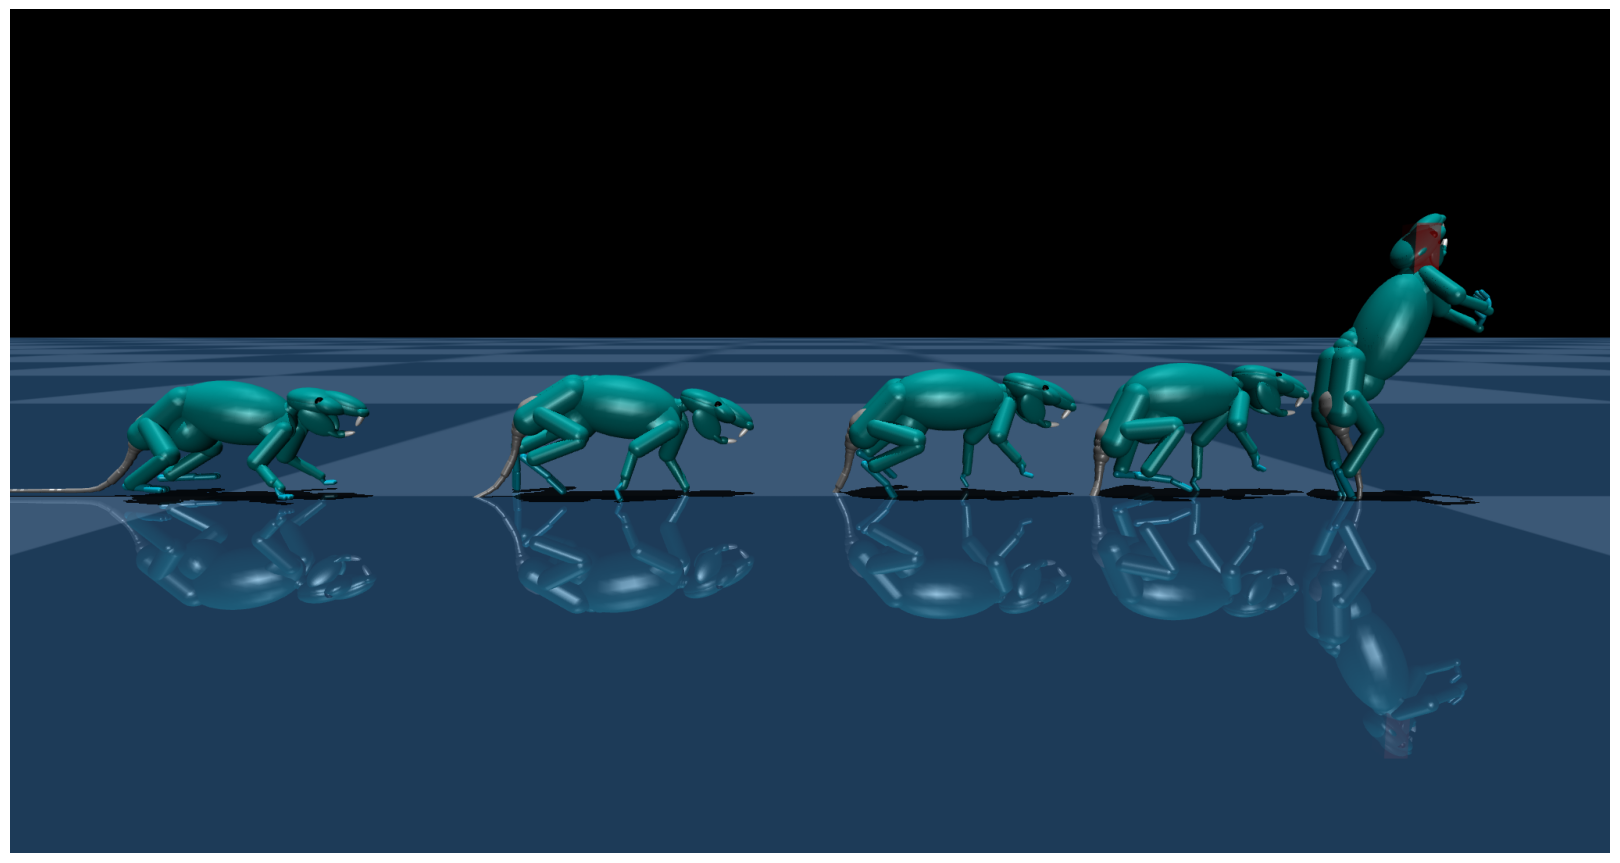

In [91]:
assert captured_cam, "Click 'Capture Camera' above first"

hires_cam = mujoco.MjvCamera()
hires_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
hires_cam.azimuth = captured_cam["azimuth"]
hires_cam.elevation = captured_cam["elevation"]
hires_cam.distance = captured_cam["distance"]
hires_cam.lookat[:] = captured_cam["lookat"]

hires_renderer = mujoco.Renderer(
    trail_model, height=TRAIL_RENDER_HEIGHT, width=TRAIL_RENDER_WIDTH
)
hires_renderer.update_scene(trail_data, camera=hires_cam)
hires_frame = hires_renderer.render().copy()
hires_renderer.close()

run_id = Path(CHECKPOINT_PATH).name
save_name = f"trail_walk_rear_distill_{run_id}_step{resolved_step}"

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(hires_frame)
ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

for ext in ["pdf", "svg", "png"]:
    fig.savefig(
        OUTPUT_DIR / f"{save_name}.{ext}", bbox_inches="tight", pad_inches=0, dpi=300
    )
print(f"Saved to {OUTPUT_DIR / save_name}.[pdf|svg|png]")
plt.show()

# Helper for Other Modes (decoder_only / scratch)

In [33]:
# Helper that loads + rolls out a walk_rear task-transfer checkpoint of any mode
# (distill / decoder_only / prior_decoder / scratch).  Uses globals defined in the
# Configuration cell (ROLLOUT_SEED, NUM_STEPS, etc.) by default.

from scamper.agent.task_transfer.walk_rear.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
)
from scamper.agent.task_transfer.walk_rear.scratch_networks import (
    make_scratch_ppo_networks,
)


def load_setup_rollout(
    checkpoint_path, step=None, rollout_seed=ROLLOUT_SEED, num_steps=NUM_STEPS
):
    """Load checkpoint, build wrapped env + inference fn, run rollout.

    Returns dict with keys: qpos, base_env, env_cfg, config, resolved_step, mode.
    """
    ckpt_info = load_task_transfer_metadata(checkpoint_path, step=step)
    cfg = ckpt_info["config"]
    resolved_step = ckpt_info["step"]
    ckpt_cfg = cfg["checkpoint_config"]
    mode = cfg["mode"]

    latent_size = ckpt_cfg["network_config"]["intention_size"]
    proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
    decoder_layer_sizes = tuple(ckpt_cfg["network_config"]["decoder_layer_sizes"])

    decoder_fn = prior_fn = None
    if mode != "scratch":
        step_prefix = "DistillNetwork" if mode == "distill" else "PriorNetwork"
        _enc, prior_params, decoder_params, im_norm, _ = load_prior_checkpoint(
            cfg["checkpoint"]["path"],
            step=cfg["checkpoint"]["step"],
            step_prefix=step_prefix,
        )
        decoder_fn = make_decoder_inference_fn(decoder_params, im_norm, ckpt_cfg)
        if mode in ("distill", "prior_decoder"):
            prior_fn = make_prior_inference_fn(prior_params, im_norm, ckpt_cfg)

    env_cfg = walk_rear.default_config()
    xml_variant = cfg["env"].get("xml_variant", "full-collisions")
    env_cfg.walker_xml_path = {
        "limited-collisions": rodent_consts.RODENT_XML_PATH,
        "full-collisions": rodent_consts.RODENT_FULL_COLLISION_XML,
        "no-tail-collisions": rodent_consts.RODENT_NO_TAIL_COLLISION_XML,
    }[xml_variant]
    env_cfg.mujoco_impl = "jax"
    env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
    env_cfg.torque_actuators = (
        cfg["scratch"]["torque_actuators"] if mode == "scratch" else True
    )
    for k in (
        "target_x",
        "target_y",
        "target_z",
        "xy_tolerance",
        "z_tolerance",
        "hold_duration",
        "distance_margin",
    ):
        setattr(env_cfg, k, cfg["env"][k])
    env_cfg.reward_terms = {
        "distance_to_target": {
            "weight": cfg["env"]["reward_weights"]["distance_to_target"]
        },
        "walk_rear_success": {
            "weight": cfg["env"]["reward_weights"]["walk_rear_success"]
        },
        "control_diff_cost": {
            "weight": cfg["env"]["reward_weights"]["control_diff_cost"]
        },
    }

    base_env = walk_rear.WalkRear(config=env_cfg)
    if mode == "decoder_only":
        env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
    elif mode == "scratch":
        env = FlatObsWrapper(base_env)
    else:  # distill or prior_decoder
        mc = cfg["distill"] if mode == "distill" else cfg["prior_decoder"]
        env = PriorDecoderHighLevelWrapper(
            base_env,
            prior_fn,
            decoder_fn,
            latent_size,
            proprio_size,
            deterministic_prior=mc["deterministic_prior"],
            noise_logvar=mc["noise_logvar"],
        )

    jit_reset_l = jax.jit(env.reset)
    jit_step_l = jax.jit(env.step)
    rng = jax.random.PRNGKey(rollout_seed)
    start_state = jit_reset_l(rng)
    obs_size = start_state.obs.shape[-1]
    action_size = env.action_size

    if mode == "scratch":
        task_obs_size = obs_size - proprio_size
        ppo_network = make_scratch_ppo_networks(
            task_obs_size=task_obs_size,
            proprio_size=proprio_size,
            action_size=action_size,
            latent_size=latent_size,
            policy_hidden_layer_sizes=tuple(cfg["network"]["policy_layers"]),
            decoder_hidden_layer_sizes=decoder_layer_sizes,
            value_hidden_layer_sizes=tuple(cfg["network"]["value_layers"]),
        )
    else:
        ppo_network = ppo_networks.make_ppo_networks(
            obs_size,
            action_size,
            preprocess_observations_fn=running_statistics.normalize,
            policy_hidden_layer_sizes=tuple(cfg["network"]["policy_layers"]),
            value_hidden_layer_sizes=tuple(cfg["network"]["value_layers"]),
        )

    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = ppo_network.policy_network.init(key_p)
    dummy_value = ppo_network.value_network.init(key_v)
    abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

    brax_params = load_task_transfer_brax_params(
        checkpoint_path=checkpoint_path,
        abstract_brax_params=abstract_brax_params,
        step=resolved_step,
    )
    norm_p, pol_p, _ = brax_params

    policy_net = ppo_network.policy_network
    pad = ppo_network.parametric_action_distribution

    @jax.jit
    def jit_inference(params, observations, key_sample):
        del key_sample
        logits = policy_net.apply(params[0], params[1], observations)
        return pad.mode(logits), {}

    inf_params = (norm_p, pol_p)

    state = start_state
    states = [state]
    act_rng = jax.random.PRNGKey(rollout_seed + 1)
    done_step = None
    for t in range(num_steps):
        act_rng, key = jax.random.split(act_rng)
        action, _ = jit_inference(inf_params, state.obs, key)
        state = jit_step_l(state, action)
        states.append(state)
        if bool(state.done) and done_step is None:
            done_step = t + 1
            print(f"[{mode}] Episode done at step {done_step}")
            break

    qpos_arr = np.stack([np.asarray(s.data.qpos) for s in states], axis=0)
    print(f"[{mode}] Rollout qpos shape: {qpos_arr.shape}")
    return {
        "qpos": qpos_arr,
        "base_env": base_env,
        "env_cfg": env_cfg,
        "config": cfg,
        "resolved_step": resolved_step,
        "mode": mode,
    }

# Decoder-Only Mode

In [49]:
CHECKPOINT_PATH_D = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/walk_rear_checkpoints/260415_193039_378422"
CHECKPOINT_STEP_D = 38  # None = latest

result_d = load_setup_rollout(
    CHECKPOINT_PATH_D,
    step=CHECKPOINT_STEP_D,
    rollout_seed=ROLLOUT_SEED,
    num_steps=NUM_STEPS,
)
qpos_d = result_d["qpos"]
base_env_d = result_d["base_env"]
env_cfg_d = result_d["env_cfg"]
config_d = result_d["config"]
resolved_step_d = result_d["resolved_step"]
target_d = np.array(
    [
        config_d["env"]["target_x"],
        config_d["env"]["target_y"],
        config_d["env"]["target_z"],
    ]
)
print(
    f"Final torso pos: xy={qpos_d[-1, :2]}, z={qpos_d[-1, 2]:.3f}  |  target={target_d}"
)

[decoder_only] Rollout qpos shape: (501, 74)
Final torso pos: xy=[ 1.0900602  -0.02489351], z=0.073  |  target=[1.  0.  0.2]


## Render Standard Video (Decoder-Only)

In [50]:
render_data_d = mujoco.MjData(base_env_d.mj_model)
cam_id_d = mujoco.mj_name2id(
    base_env_d.mj_model, mujoco.mjtObj.mjOBJ_CAMERA, RENDER_CAMERA
)

renderer_d = mujoco.Renderer(
    base_env_d.mj_model, height=RENDER_HEIGHT, width=RENDER_WIDTH
)
frames_d = []
for t in range(qpos_d.shape[0]):
    render_data_d.qpos[:] = qpos_d[t]
    mujoco.mj_forward(base_env_d.mj_model, render_data_d)
    renderer_d.update_scene(render_data_d, camera=cam_id_d)
    frames_d.append(renderer_d.render().copy())
renderer_d.close()
print(f"Rendered {len(frames_d)} frames")
media.show_video(frames_d, fps=RENDER_FPS)

Rendered 501 frames


This browser does not support the video tag.


## Build Trail Scene + Interactive Viewer (Decoder-Only) — adjust camera, then Capture

In [60]:
# === Per-run overrides (edit these) ===
TRAIL_T_START_D = TRAIL_T_START
TRAIL_T_END_D = TRAIL_T_END
TRAIL_NUM_FRAMES_D = TRAIL_NUM_FRAMES
TRAIL_TIMESTEPS_D = [0, 60, 120, 175, 290]  # explicit timesteps; empty = linspace

walker_xml = str(env_cfg_d.walker_xml_path)
arena_xml = str(env_cfg_d.arena_xml_path)

T = qpos_d.shape[0]
if TRAIL_TIMESTEPS_D:
    trail_indices_d = np.array(TRAIL_TIMESTEPS_D, dtype=int)
else:
    t_end = min(TRAIL_T_END_D, T - 1)
    trail_indices_d = np.linspace(TRAIL_T_START_D, t_end, TRAIL_NUM_FRAMES_D, dtype=int)
trail_num_frames_d = len(trail_indices_d)
print(f"{trail_num_frames_d} poses at timesteps: {trail_indices_d.tolist()}")

trail_spec = mujoco.MjSpec.from_file(arena_xml)
for i in range(trail_num_frames_d):
    rs = mujoco.MjSpec.from_file(walker_xml)
    fr = trail_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    bd = fr.attach_body(rs.body("walker"), "", suffix=f"-t{i}")
    bd.add_freejoint(name=f"root-t{i}")

trail_spec.worldbody.add_geom(
    name="target_box",
    type=mujoco.mjtGeom.mjGEOM_BOX,
    pos=[env_cfg_d.target_x, env_cfg_d.target_y, env_cfg_d.target_z],
    size=[env_cfg_d.xy_tolerance, env_cfg_d.xy_tolerance, env_cfg_d.z_tolerance],
    rgba=[1.0, 0.0, 0.0, 0.3],
    contype=0,
    conaffinity=0,
)

cam_pos = np.array(TRAIL_CAM_POS, dtype=float)
cam_lookat = np.array(TRAIL_CAM_LOOKAT, dtype=float)
look_dir = cam_lookat - cam_pos
cam_z = -look_dir / np.linalg.norm(look_dir)
cam_x = np.cross(np.array([0.0, 0.0, 1.0]), cam_z)
cam_x /= np.linalg.norm(cam_x)
cam_y = np.cross(cam_z, cam_x)
R = np.column_stack([cam_x, cam_y, cam_z])
trace = R[0, 0] + R[1, 1] + R[2, 2]
s = 2.0 * np.sqrt(1.0 + trace)
cam_quat = [
    0.25 * s,
    (R[2, 1] - R[1, 2]) / s,
    (R[0, 2] - R[2, 0]) / s,
    (R[1, 0] - R[0, 1]) / s,
]
ovc = trail_spec.worldbody.add_camera(name="trail_overview")
ovc.pos = cam_pos.tolist()
ovc.quat = cam_quat
ovc.fovy = TRAIL_CAM_FOVY

oh = trail_spec.worldbody.add_light(name="overhead")
oh.pos = [0.0, 0.0, 10.0]
oh.dir = [0, 0, -1]
oh.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
oh.diffuse = [1.0, 1.0, 1.0]
oh.specular = [0.3, 0.3, 0.3]

trail_model_d = trail_spec.compile()
for i in range(trail_model_d.nlight):
    ln = mujoco.mj_id2name(trail_model_d, mujoco.mjtObj.mjOBJ_LIGHT, i)
    if ln and "tracking_light" in ln:
        trail_model_d.light_diffuse[i] = [0, 0, 0]
        trail_model_d.light_specular[i] = [0, 0, 0]

trail_data_d = mujoco.MjData(trail_model_d)
nq_single_d = base_env_d.mj_model.nq
for i, t in enumerate(trail_indices_d):
    trail_data_d.qpos[i * nq_single_d : (i + 1) * nq_single_d] = qpos_d[t]
mujoco.mj_forward(trail_model_d, trail_data_d)

# Interactive viewer
interactive_renderer_d = mujoco.Renderer(trail_model_d, height=1080, width=2048)
free_cam_d = mujoco.MjvCamera()
free_cam_d.type = mujoco.mjtCamera.mjCAMERA_FREE

try:
    _has_capture = bool(captured_cam_d)
except NameError:
    captured_cam_d = {}
    _has_capture = False

if _has_capture:
    free_cam_d.azimuth = captured_cam_d["azimuth"]
    free_cam_d.elevation = captured_cam_d["elevation"]
    free_cam_d.distance = captured_cam_d["distance"]
    free_cam_d.lookat[:] = captured_cam_d["lookat"]
else:
    free_cam_d.lookat[:] = TRAIL_CAM_LOOKAT
    free_cam_d.distance = float(
        np.linalg.norm(np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT))
    )
    _offset = np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)
    free_cam_d.azimuth = float(np.degrees(np.arctan2(_offset[1], _offset[0])))
    free_cam_d.elevation = float(
        np.degrees(np.arcsin(_offset[2] / np.linalg.norm(_offset)))
    )

img_widget_d = widgets.Image(format="jpeg", layout=widgets.Layout(width="2048px"))


def render_view_d(change=None):
    interactive_renderer_d.update_scene(trail_data_d, camera=free_cam_d)
    f = interactive_renderer_d.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(f).save(buf, format="JPEG", quality=90)
    img_widget_d.value = buf.getvalue()


az_d = widgets.FloatSlider(
    value=free_cam_d.azimuth,
    min=-180,
    max=180,
    step=1,
    description="Azimuth",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
el_d = widgets.FloatSlider(
    value=free_cam_d.elevation,
    min=-90,
    max=90,
    step=1,
    description="Elevation",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
dist_d = widgets.FloatSlider(
    value=free_cam_d.distance,
    min=0.1,
    max=5.0,
    step=0.05,
    description="Distance",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lx_d = widgets.FloatSlider(
    value=free_cam_d.lookat[0],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat X",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
ly_d = widgets.FloatSlider(
    value=free_cam_d.lookat[1],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat Y",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lz_d = widgets.FloatSlider(
    value=free_cam_d.lookat[2],
    min=-1,
    max=2,
    step=0.05,
    description="Lookat Z",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)


def on_change_d(change):
    free_cam_d.azimuth = az_d.value
    free_cam_d.elevation = el_d.value
    free_cam_d.distance = dist_d.value
    free_cam_d.lookat[:] = [lx_d.value, ly_d.value, lz_d.value]
    render_view_d()


for sl in [az_d, el_d, dist_d, lx_d, ly_d, lz_d]:
    sl.observe(on_change_d, names="value")

cap_label_d = widgets.Label(value="")
cap_btn_d = widgets.Button(description="Capture Camera", button_style="success")


def on_capture_d(btn):
    captured_cam_d["azimuth"] = az_d.value
    captured_cam_d["elevation"] = el_d.value
    captured_cam_d["distance"] = dist_d.value
    captured_cam_d["lookat"] = [lx_d.value, ly_d.value, lz_d.value]
    cap_label_d.value = (
        f"Captured: az={captured_cam_d['azimuth']:.1f} el={captured_cam_d['elevation']:.1f} "
        f"dist={captured_cam_d['distance']:.2f} lookat={captured_cam_d['lookat']}"
    )


cap_btn_d.on_click(on_capture_d)
render_view_d()

ipy_display(
    widgets.VBox(
        [
            img_widget_d,
            widgets.VBox(
                [
                    widgets.HBox([az_d, el_d]),
                    widgets.HBox([dist_d]),
                    widgets.HBox([lx_d, ly_d, lz_d]),
                    widgets.HBox([cap_btn_d, cap_label_d]),
                ]
            ),
        ]
    )
)

5 poses at timesteps: [0, 60, 120, 175, 290]


## High-Res Render and Save (Decoder-Only)

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/walk_rear_distill_trails/trail_walk_rear_decoder_only_260415_193039_378422_step38.[pdf|svg|png]


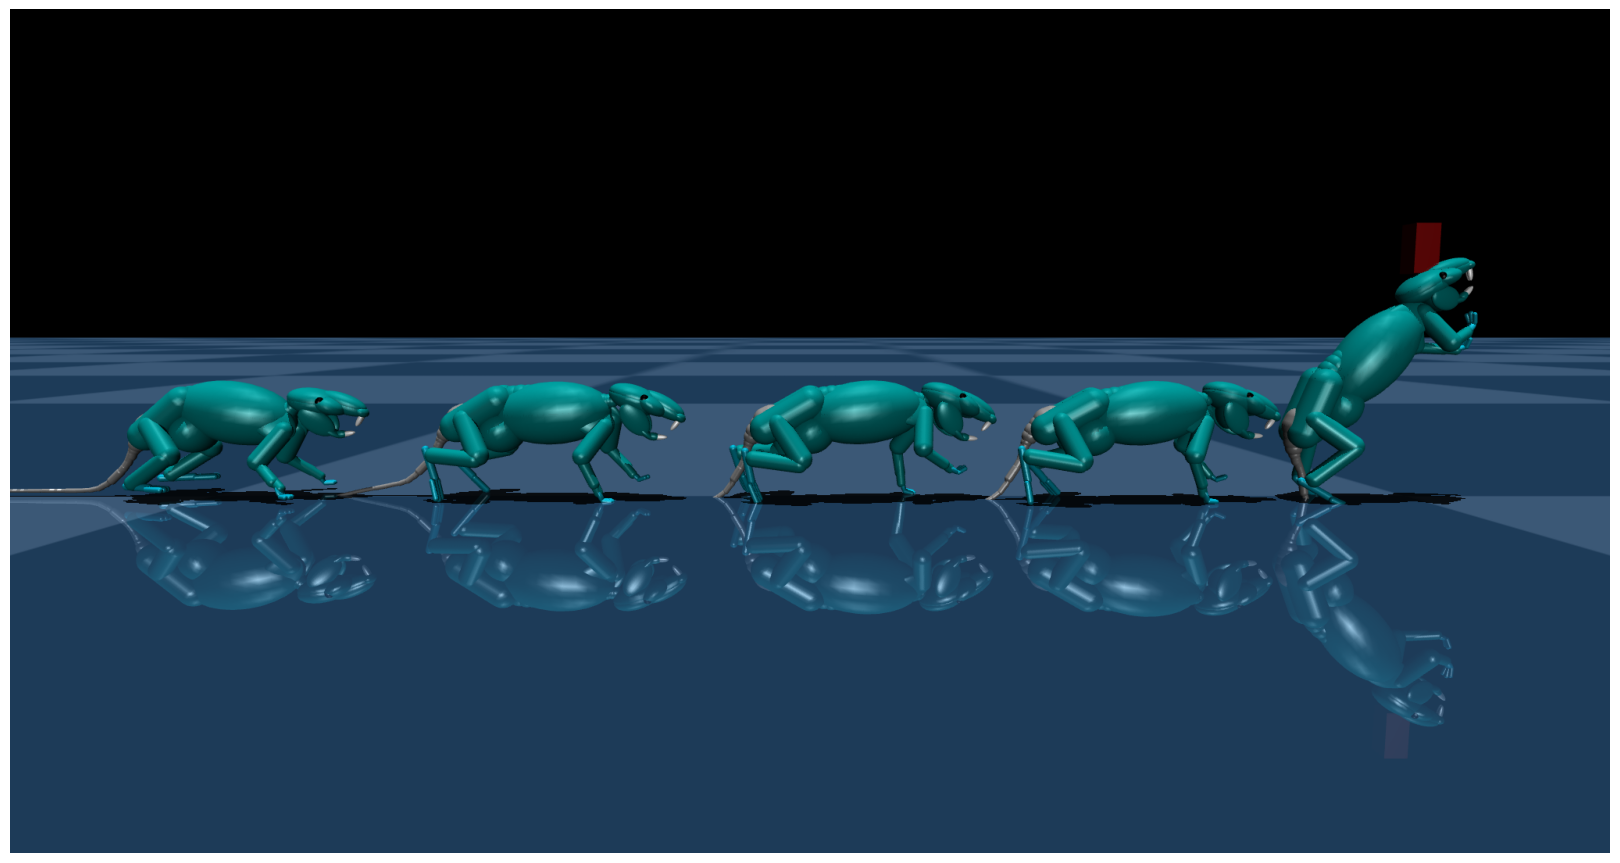

In [92]:
assert captured_cam_d, "Click 'Capture Camera' above first"

hires_cam_d = mujoco.MjvCamera()
hires_cam_d.type = mujoco.mjtCamera.mjCAMERA_FREE
hires_cam_d.azimuth = captured_cam_d["azimuth"]
hires_cam_d.elevation = captured_cam_d["elevation"]
hires_cam_d.distance = captured_cam_d["distance"]
hires_cam_d.lookat[:] = captured_cam_d["lookat"]

hires_renderer_d = mujoco.Renderer(
    trail_model_d, height=TRAIL_RENDER_HEIGHT, width=TRAIL_RENDER_WIDTH
)
hires_renderer_d.update_scene(trail_data_d, camera=hires_cam_d)
hires_frame_d = hires_renderer_d.render().copy()
hires_renderer_d.close()

run_id_d = Path(CHECKPOINT_PATH_D).name
save_name_d = f"trail_walk_rear_decoder_only_{run_id_d}_step{resolved_step_d}"

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(hires_frame_d)
ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
for ext in ["pdf", "svg", "png"]:
    fig.savefig(
        OUTPUT_DIR / f"{save_name_d}.{ext}", bbox_inches="tight", pad_inches=0, dpi=300
    )
print(f"Saved to {OUTPUT_DIR / save_name_d}.[pdf|svg|png]")
plt.show()

# Scratch Mode

In [62]:
CHECKPOINT_PATH_S = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/walk_rear_checkpoints/260415_192952_497895"
CHECKPOINT_STEP_S = 39  # None = latest

result_s = load_setup_rollout(
    CHECKPOINT_PATH_S,
    step=CHECKPOINT_STEP_S,
    rollout_seed=ROLLOUT_SEED,
    num_steps=NUM_STEPS,
)
qpos_s = result_s["qpos"]
base_env_s = result_s["base_env"]
env_cfg_s = result_s["env_cfg"]
config_s = result_s["config"]
resolved_step_s = result_s["resolved_step"]
target_s = np.array(
    [
        config_s["env"]["target_x"],
        config_s["env"]["target_y"],
        config_s["env"]["target_z"],
    ]
)
print(
    f"Final torso pos: xy={qpos_s[-1, :2]}, z={qpos_s[-1, 2]:.3f}  |  target={target_s}"
)

[scratch] Rollout qpos shape: (501, 74)
Final torso pos: xy=[1.0138409 0.0042796], z=0.060  |  target=[1.  0.  0.2]


## Render Standard Video (Scratch)

In [63]:
render_data_s = mujoco.MjData(base_env_s.mj_model)
cam_id_s = mujoco.mj_name2id(
    base_env_s.mj_model, mujoco.mjtObj.mjOBJ_CAMERA, RENDER_CAMERA
)

renderer_s = mujoco.Renderer(
    base_env_s.mj_model, height=RENDER_HEIGHT, width=RENDER_WIDTH
)
frames_s = []
for t in range(qpos_s.shape[0]):
    render_data_s.qpos[:] = qpos_s[t]
    mujoco.mj_forward(base_env_s.mj_model, render_data_s)
    renderer_s.update_scene(render_data_s, camera=cam_id_s)
    frames_s.append(renderer_s.render().copy())
renderer_s.close()
print(f"Rendered {len(frames_s)} frames")
media.show_video(frames_s, fps=RENDER_FPS)

Rendered 501 frames


This browser does not support the video tag.


## Build Trail Scene + Interactive Viewer (Scratch) — adjust camera, then Capture

In [87]:
# === Per-run overrides (edit these) ===
TRAIL_T_START_S = TRAIL_T_START
TRAIL_T_END_S = TRAIL_T_END
TRAIL_NUM_FRAMES_S = TRAIL_NUM_FRAMES
TRAIL_TIMESTEPS_S = [0, 28, 40, 55, 300]  # explicit timesteps; empty = linspace

walker_xml = str(env_cfg_s.walker_xml_path)
arena_xml = str(env_cfg_s.arena_xml_path)

T = qpos_s.shape[0]
if TRAIL_TIMESTEPS_S:
    trail_indices_s = np.array(TRAIL_TIMESTEPS_S, dtype=int)
else:
    t_end = min(TRAIL_T_END_S, T - 1)
    trail_indices_s = np.linspace(TRAIL_T_START_S, t_end, TRAIL_NUM_FRAMES_S, dtype=int)
trail_num_frames_s = len(trail_indices_s)
print(f"{trail_num_frames_s} poses at timesteps: {trail_indices_s.tolist()}")

trail_spec = mujoco.MjSpec.from_file(arena_xml)
for i in range(trail_num_frames_s):
    rs = mujoco.MjSpec.from_file(walker_xml)
    fr = trail_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    bd = fr.attach_body(rs.body("walker"), "", suffix=f"-t{i}")
    bd.add_freejoint(name=f"root-t{i}")

trail_spec.worldbody.add_geom(
    name="target_box",
    type=mujoco.mjtGeom.mjGEOM_BOX,
    pos=[env_cfg_s.target_x, env_cfg_s.target_y, env_cfg_s.target_z],
    size=[env_cfg_s.xy_tolerance, env_cfg_s.xy_tolerance, env_cfg_s.z_tolerance],
    rgba=[1.0, 0.0, 0.0, 0.3],
    contype=0,
    conaffinity=0,
)

cam_pos = np.array(TRAIL_CAM_POS, dtype=float)
cam_lookat = np.array(TRAIL_CAM_LOOKAT, dtype=float)
look_dir = cam_lookat - cam_pos
cam_z = -look_dir / np.linalg.norm(look_dir)
cam_x = np.cross(np.array([0.0, 0.0, 1.0]), cam_z)
cam_x /= np.linalg.norm(cam_x)
cam_y = np.cross(cam_z, cam_x)
R = np.column_stack([cam_x, cam_y, cam_z])
trace = R[0, 0] + R[1, 1] + R[2, 2]
s = 2.0 * np.sqrt(1.0 + trace)
cam_quat = [
    0.25 * s,
    (R[2, 1] - R[1, 2]) / s,
    (R[0, 2] - R[2, 0]) / s,
    (R[1, 0] - R[0, 1]) / s,
]
ovc = trail_spec.worldbody.add_camera(name="trail_overview")
ovc.pos = cam_pos.tolist()
ovc.quat = cam_quat
ovc.fovy = TRAIL_CAM_FOVY

oh = trail_spec.worldbody.add_light(name="overhead")
oh.pos = [0.0, 0.0, 10.0]
oh.dir = [0, 0, -1]
oh.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
oh.diffuse = [1.0, 1.0, 1.0]
oh.specular = [0.3, 0.3, 0.3]

trail_model_s = trail_spec.compile()
for i in range(trail_model_s.nlight):
    ln = mujoco.mj_id2name(trail_model_s, mujoco.mjtObj.mjOBJ_LIGHT, i)
    if ln and "tracking_light" in ln:
        trail_model_s.light_diffuse[i] = [0, 0, 0]
        trail_model_s.light_specular[i] = [0, 0, 0]

trail_data_s = mujoco.MjData(trail_model_s)
nq_single_s = base_env_s.mj_model.nq
for i, t in enumerate(trail_indices_s):
    trail_data_s.qpos[i * nq_single_s : (i + 1) * nq_single_s] = qpos_s[t]
mujoco.mj_forward(trail_model_s, trail_data_s)

# Interactive viewer
interactive_renderer_s = mujoco.Renderer(trail_model_s, height=1080, width=2048)
free_cam_s = mujoco.MjvCamera()
free_cam_s.type = mujoco.mjtCamera.mjCAMERA_FREE

try:
    _has_capture = bool(captured_cam_s)
except NameError:
    captured_cam_s = {}
    _has_capture = False

if _has_capture:
    free_cam_s.azimuth = captured_cam_s["azimuth"]
    free_cam_s.elevation = captured_cam_s["elevation"]
    free_cam_s.distance = captured_cam_s["distance"]
    free_cam_s.lookat[:] = captured_cam_s["lookat"]
else:
    free_cam_s.lookat[:] = TRAIL_CAM_LOOKAT
    free_cam_s.distance = float(
        np.linalg.norm(np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT))
    )
    _offset = np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)
    free_cam_s.azimuth = float(np.degrees(np.arctan2(_offset[1], _offset[0])))
    free_cam_s.elevation = float(
        np.degrees(np.arcsin(_offset[2] / np.linalg.norm(_offset)))
    )

img_widget_s = widgets.Image(format="jpeg", layout=widgets.Layout(width="2048px"))


def render_view_s(change=None):
    interactive_renderer_s.update_scene(trail_data_s, camera=free_cam_s)
    f = interactive_renderer_s.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(f).save(buf, format="JPEG", quality=90)
    img_widget_s.value = buf.getvalue()


az_s = widgets.FloatSlider(
    value=free_cam_s.azimuth,
    min=-180,
    max=180,
    step=1,
    description="Azimuth",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
el_s = widgets.FloatSlider(
    value=free_cam_s.elevation,
    min=-90,
    max=90,
    step=1,
    description="Elevation",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
dist_s = widgets.FloatSlider(
    value=free_cam_s.distance,
    min=0.1,
    max=5.0,
    step=0.05,
    description="Distance",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lx_s = widgets.FloatSlider(
    value=free_cam_s.lookat[0],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat X",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
ly_s = widgets.FloatSlider(
    value=free_cam_s.lookat[1],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat Y",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lz_s = widgets.FloatSlider(
    value=free_cam_s.lookat[2],
    min=-1,
    max=2,
    step=0.05,
    description="Lookat Z",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)


def on_change_s(change):
    free_cam_s.azimuth = az_s.value
    free_cam_s.elevation = el_s.value
    free_cam_s.distance = dist_s.value
    free_cam_s.lookat[:] = [lx_s.value, ly_s.value, lz_s.value]
    render_view_s()


for sl in [az_s, el_s, dist_s, lx_s, ly_s, lz_s]:
    sl.observe(on_change_s, names="value")

cap_label_s = widgets.Label(value="")
cap_btn_s = widgets.Button(description="Capture Camera", button_style="success")


def on_capture_s(btn):
    captured_cam_s["azimuth"] = az_s.value
    captured_cam_s["elevation"] = el_s.value
    captured_cam_s["distance"] = dist_s.value
    captured_cam_s["lookat"] = [lx_s.value, ly_s.value, lz_s.value]
    cap_label_s.value = (
        f"Captured: az={captured_cam_s['azimuth']:.1f} el={captured_cam_s['elevation']:.1f} "
        f"dist={captured_cam_s['distance']:.2f} lookat={captured_cam_s['lookat']}"
    )


cap_btn_s.on_click(on_capture_s)
render_view_s()

ipy_display(
    widgets.VBox(
        [
            img_widget_s,
            widgets.VBox(
                [
                    widgets.HBox([az_s, el_s]),
                    widgets.HBox([dist_s]),
                    widgets.HBox([lx_s, ly_s, lz_s]),
                    widgets.HBox([cap_btn_s, cap_label_s]),
                ]
            ),
        ]
    )
)

5 poses at timesteps: [0, 28, 40, 55, 300]


## High-Res Render and Save (Scratch)

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/walk_rear_distill_trails/trail_walk_rear_scratch_260415_192952_497895_step39.[pdf|svg|png]


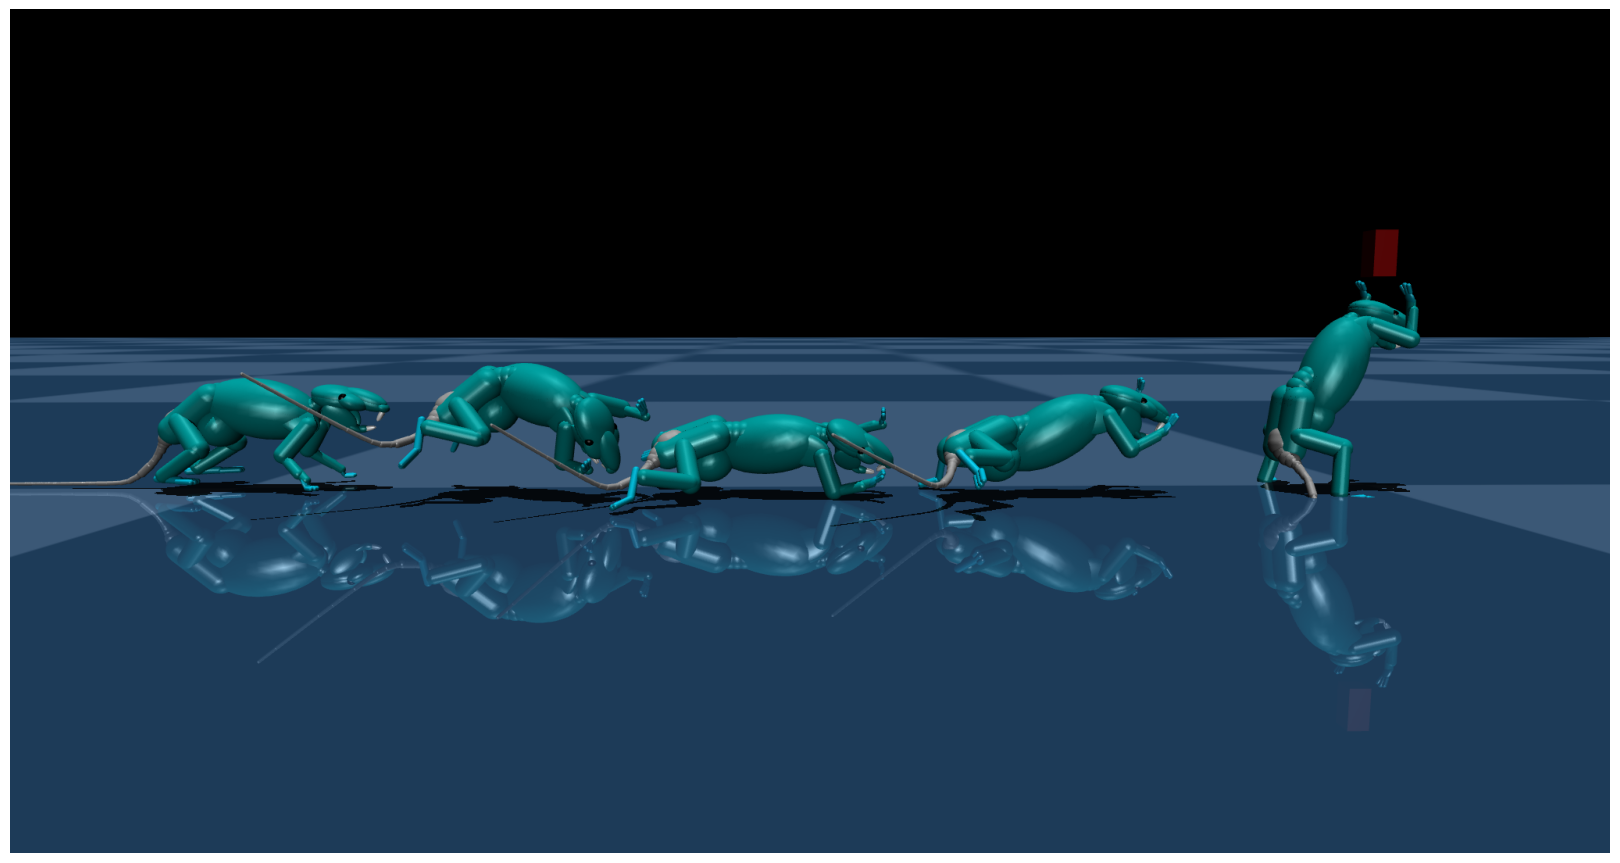

In [93]:
assert captured_cam_s, "Click 'Capture Camera' above first"

hires_cam_s = mujoco.MjvCamera()
hires_cam_s.type = mujoco.mjtCamera.mjCAMERA_FREE
hires_cam_s.azimuth = captured_cam_s["azimuth"]
hires_cam_s.elevation = captured_cam_s["elevation"]
hires_cam_s.distance = captured_cam_s["distance"]
hires_cam_s.lookat[:] = captured_cam_s["lookat"]

hires_renderer_s = mujoco.Renderer(
    trail_model_s, height=TRAIL_RENDER_HEIGHT, width=TRAIL_RENDER_WIDTH
)
hires_renderer_s.update_scene(trail_data_s, camera=hires_cam_s)
hires_frame_s = hires_renderer_s.render().copy()
hires_renderer_s.close()

run_id_s = Path(CHECKPOINT_PATH_S).name
save_name_s = f"trail_walk_rear_scratch_{run_id_s}_step{resolved_step_s}"

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(hires_frame_s)
ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
for ext in ["pdf", "svg", "png"]:
    fig.savefig(
        OUTPUT_DIR / f"{save_name_s}.{ext}", bbox_inches="tight", pad_inches=0, dpi=300
    )
print(f"Saved to {OUTPUT_DIR / save_name_s}.[pdf|svg|png]")
plt.show()